# MIS 5480: Recommendations and Engagement
## Group 4 | KuaiRand-Pure
Question: How does observed engagement differ between regular recommendations and randomly shown videos?

This is a descriptive analysis of short-video platform Kuaishou. The initial comparison uses two files covering April 22-May 8, 2022. We also use an earlier log (April 8-21) as history. The "Pure" dataset retains a restricted candidate video pool. We compare one shared feed setting (tab = 1), the setting with the most observations in both groups.

Random exposure gives us a baseline that is not shaped by the algorithm's earlier predictions. Steps 1-5 are our first-draft comparison. Steps 6-9 extend our analysis to three questions:

1. **Engagement gap:** How much more do users engage with algorithm-chosen videos than with randomly inserted ones, and does that hold for the same users?
2. **Familiarity effect:** Do users engage more with *randomly shown* videos whose topic the algorithm previously fed them? 
3. **Narrowing exposure:** Is the algorithm's feed narrower and more concentrated than a random feed? 

In [1]:
import os
# set working directory
os.chdir(r"C:\Users\taylo\OneDrive\Documents\Grad School\MIS 5480\Group Project")
print(os.getcwd())

C:\Users\taylo\OneDrive\Documents\Grad School\MIS 5480\Group Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# only bring in the columns we use and store them as ints because the logs are large (2.6 million rows)
LOG_COLS = ["user_id", "video_id", "date", "time_ms", "tab", "is_rand", "is_click", "is_like", "long_view"]
LOG_DTYPES = {"user_id": "int32", "video_id": "int16", "date": "int32", "time_ms": "int64",
              "tab": "int8", "is_rand": "int8", "is_click": "int8", "is_like": "int8", "long_view": "int8"}

regular = pd.read_csv("KuaiRand-Pure/data/log_standard_4_22_to_5_08_pure.csv", usecols=LOG_COLS, dtype=LOG_DTYPES)
random = pd.read_csv("KuaiRand-Pure/data/log_random_4_22_to_5_08_pure.csv", usecols=LOG_COLS, dtype=LOG_DTYPES)

# also bring in earlier log data as history to analyze historical changes, plus user and video data
regular_p1 = pd.read_csv("KuaiRand-Pure/data/log_standard_4_08_to_4_21_pure.csv", usecols=LOG_COLS, dtype=LOG_DTYPES)
users = pd.read_csv("KuaiRand-Pure/data/user_features_pure.csv", usecols=["user_id", "user_active_degree", "is_live_streamer"])
videos = pd.read_csv("KuaiRand-Pure/data/video_features_basic_pure.csv", usecols=["video_id", "tag", "video_type"])

print("Regular rows and columns:", regular.shape)
print("Random rows and columns:", random.shape)
print("Column names:", regular.columns.tolist())
print("Regular (Apr 8-21) rows and columns:", regular_p1.shape)
print("Users:", users.shape, "| Videos:", videos.shape)

Regular rows and columns: (295497, 9)
Random rows and columns: (1186059, 9)
Column names: ['user_id', 'video_id', 'date', 'time_ms', 'is_click', 'is_like', 'long_view', 'is_rand', 'tab']
Regular (Apr 8-21) rows and columns: (1141112, 9)
Users: (27285, 3) | Videos: (7583, 3)


## Data Prep: Prepare the logs
*Change from our first draft.* The three logs are large and we now use the April 8-21 log as well, so before inspecting the data it is important to check for duplicates.

We treat a row as a duplicate when every field we load matches, including the millisecond timestamp (same user, same video, same instant, same responses). These are logging repeats, not repeat views, and they would double-count appearances. We remove them *before* narrowing to the fields used in Step 1, because once the timestamp is dropped an actual repeat view can no longer be told apart from a logging repeat.

In [4]:
rows_before = {"Regular, Apr 8-21": len(regular_p1),
               "Regular, Apr 22-May 8": len(regular),
               "Random, Apr 22-May 8": len(random)}

regular_p1 = regular_p1.drop_duplicates()
regular = regular.drop_duplicates()
random = random.drop_duplicates()

rows_after = {"Regular, Apr 8-21": len(regular_p1),
              "Regular, Apr 22-May 8": len(regular),
              "Random, Apr 22-May 8": len(random)}

dedupe = pd.DataFrame({"rows_before": rows_before, "rows_after": rows_after})
dedupe["removed"] = dedupe["rows_before"] - dedupe["rows_after"]
dedupe["removed_%"] = (100 * dedupe["removed"] / dedupe["rows_before"]).round(2)
print(dedupe.to_string())

# Rows sharing user, video and timestamp but with different responses are kept (they are not exact repeats)
still_dup = sum(int(df.duplicated(["user_id", "video_id", "time_ms"]).sum()) for df in (regular_p1, regular, random))
print("\nRows still sharing (user, video, timestamp) after de-duplication:", still_dup)

                       rows_before  rows_after  removed  removed_%
Regular, Apr 8-21          1141112     1124588    16524       1.45
Regular, Apr 22-May 8       295497      288662     6835       2.31
Random, Apr 22-May 8       1186059     1186049       10       0.00

Rows still sharing (user, video, timestamp) after de-duplication: 114


## Step 1: Inspect and check the data
Each row is a logged video appearance and response. Users can appear many times. **is_like** is 1 for a like and 0 otherwise. **long_view** is 1 for watching the full duration when a video is at most 18 seconds, or at least 18 seconds for a longer video. **tab** identifies the feed setting. **is_rand** identifies random intervention. A zero does not necessarily mean dislike.

We inspect only the fields needed for this analysis. No missing values were found in the selected fields, so no rows were removed for missing data.

In [5]:
columns = ["user_id", "video_id", "date", "tab",
           "is_rand", "is_click", "is_like", "long_view"]
regular = regular[columns].copy()
random = random[columns].copy()
regular_p1 = regular_p1[columns].copy()

print("First 5 regular records:")
print(regular.head().to_string(index=False))
print("\nData types:")
print(regular.dtypes)
print("\nMissing values in selected fields:")
print(pd.DataFrame({"Regular": regular.isna().sum(),
                    "Random": random.isna().sum()}))
print("\nRegular exposure labels:", regular["is_rand"].unique())
print("Random exposure labels:", random["is_rand"].unique())
for column in ["is_click", "is_like", "long_view"]:
    print(column, "regular:", regular[column].unique(),
          "random:", random[column].unique())

First 5 regular records:
 user_id  video_id     date  tab  is_rand  is_click  is_like  long_view
       0      7531 20220422    0        0         0        0          0
       0      4214 20220425    1        0         0        0          0
       0      3978 20220429    0        0         0        0          0
       0       160 20220430    1        0         0        0          0
       0      6946 20220502    1        0         0        0          0

Data types:
user_id      int32
video_id     int16
date         int32
tab           int8
is_rand       int8
is_click      int8
is_like       int8
long_view     int8
dtype: object

Missing values in selected fields:
           Regular  Random
user_id          0       0
video_id         0       0
date             0       0
tab              0       0
is_rand          0       0
is_click         0       0
is_like          0       0
long_view        0       0

Regular exposure labels: [0]
Random exposure labels: [1]
is_click regular: [0 1] ran

## Step 2: Prepare Shared Comparison
Label the groups, combine the files, and keep tab = 1. This avoids mixing different feed settings. It does not make the groups identical in users or videos. The missing-value and binary-label checks above show whether the selected fields are ready for analysis and it was found that no missing-value removal is needed for these supplied files.

In [6]:
regular["exposure"] = "Regular"
random["exposure"] = "Random"
data = pd.concat([regular, random], ignore_index=True)

print("Counts before filtering:")
print(pd.crosstab(data["tab"], data["exposure"]))

comparison = data[data["tab"] == 1].copy()
print("\nDate range:", comparison["date"].min(),
      "to", comparison["date"].max())
print("\nRows retained:", len(comparison))

Counts before filtering:
exposure   Random  Regular
tab                       
0               0    28044
1         1178025   223513
2             764     9073
3               0      440
4               0    17641
5               0      397
6               0     6679
7               0      171
8               0     1358
9               0      192
10              0       72
11           6745      308
12              0      638
13              0      116
14            515       20

Date range: 20220422 to 20220508

Rows retained: 1401538


## Step 3: Summarize Engagement
For a binary 0/1 field, its mean is the proportion of rows = 1. Multiplying by 100 gives a percentage. These rates use video appearances as the denominator, not unique users. Counts are included because the two groups have different sizes.

In [7]:
summary = comparison.groupby("exposure").agg(
    appearances=("video_id", "size"),
    users=("user_id", "nunique"),
    clicks=("is_click", "sum"),
    likes=("is_like", "sum"),
    long_views=("long_view", "sum"),
    click_rate=("is_click", "mean"),
    like_rate=("is_like", "mean"),
    long_view_rate=("long_view", "mean")
)
summary["click_percent"] = summary["click_rate"] * 100
summary["like_percent"] = summary["like_rate"] * 100
summary["long_view_percent"] = summary["long_view_rate"] * 100

print(summary[["appearances", "users", "clicks", "likes", "long_views"]].to_string())
print("\nEngagement percentages:")
print(summary[["click_percent", "like_percent", "long_view_percent"]].round(2).to_string())

          appearances  users  clicks  likes  long_views
exposure                                               
Random        1178025  27000  208847   5672      100542
Regular        223513  24537  111332   4477       78592

Engagement percentages:
          click_percent  like_percent  long_view_percent
exposure                                                
Random            17.73          0.48               8.53
Regular           49.81          2.00              35.16


# Step 4: Visualize the Results

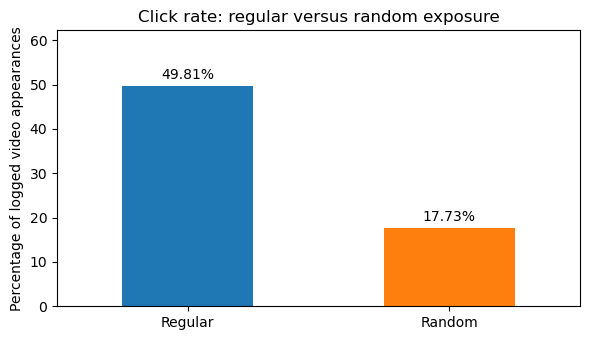

In [8]:
values = summary.reindex(["Regular", "Random"])["click_percent"]
ax = values.plot.bar(color=["C0", "C1"], figsize=(6, 3.5))
ax.set_title("Click rate: regular versus random exposure")
ax.set_ylabel("Percentage of logged video appearances")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.set_ylim(0, values.max() * 1.25)
for position, value in enumerate(values):
    ax.text(position, value + values.max() * 0.03,
            f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

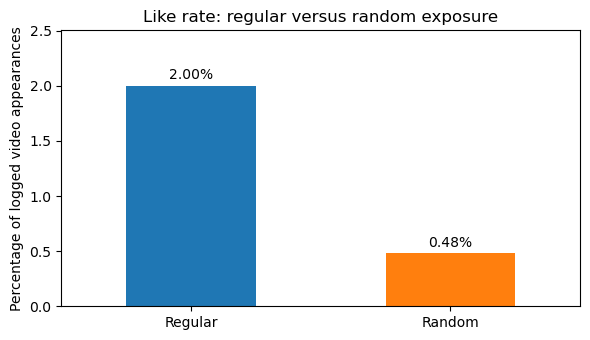

In [9]:
values = summary.reindex(["Regular", "Random"])["like_percent"]
ax = values.plot.bar(color=["C0", "C1"], figsize=(6, 3.5))
ax.set_title("Like rate: regular versus random exposure")
ax.set_ylabel("Percentage of logged video appearances")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.set_ylim(0, values.max() * 1.25)
for position, value in enumerate(values):
    ax.text(position, value + values.max() * 0.03,
            f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

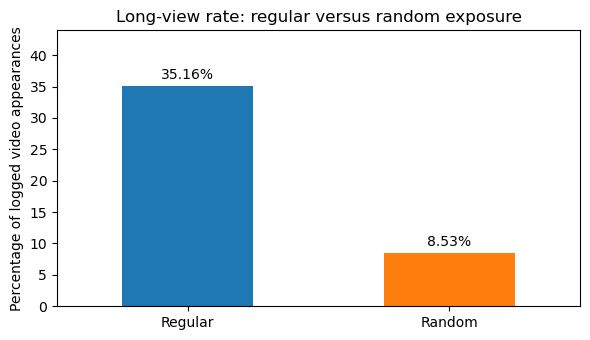

In [10]:
values = summary.reindex(["Regular", "Random"])["long_view_percent"]
ax = values.plot.bar(color=["C0", "C1"], figsize=(6, 3.5))
ax.set_title("Long-view rate: regular versus random exposure")
ax.set_ylabel("Percentage of logged video appearances")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.set_ylim(0, values.max() * 1.25)
for position, value in enumerate(values):
    ax.text(position, value + values.max() * 0.03,
            f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

## Step 5: Findings and Analysis
In feed setting 1, regular recommendations received likes on 2% of appearances, compared with 0.48% for randomly shown videos. Long views occurred on 35.16% and 8.53%, and clicks on 49.81% and 17.73%, respectively. These are observed differences in engagement, not proof that recommendations changed preferences.

## Step 6: Bring in user and video information
*Steps 6-9 extend our first draft.* So far, we have used only the logs. The user and video tables let us split results by user activity level and by video topic (`tag`). They also contain values that would mislead us if used as-is, so we inspect them first.

In [11]:
print("is_live_streamer values:", users["is_live_streamer"].value_counts().to_dict())
print("user_active_degree values:", users["user_active_degree"].value_counts().to_dict())
print("video_type values:", videos["video_type"].value_counts().to_dict())
print("\ntag column type:", videos["tag"].dtype, "| missing tags:", int(videos["tag"].isna().sum()))
print("Example tag values:", videos["tag"].dropna().sample(8, random_state=1).tolist())
print("Videos whose tag field lists more than one topic:", int(videos["tag"].str.contains(",", na=False).sum()), "of", len(videos))

is_live_streamer values: {-124: 21127, 1: 6158}
user_active_degree values: {'full_active': 17959, 'high_active': 6158, 'middle_active': 2133, '2_14_day_new': 635, 'low_active': 300, 'single_low_active': 68, '30day_retention': 15, 'day_new': 11, 'UNKNOWN': 6}
video_type values: {'NORMAL': 7506, 'AD': 76, 'UNKNOWN': 1}

tag column type: object | missing tags: 96
Example tag values: ['39', '39', '9', '39', '8', '39,43', '39,68', '39']
Videos whose tag field lists more than one topic: 1791 of 7583


**What the above checks show:**

- In `user_features`, `is_live_streamer` uses **-124** for most users. That is a placeholder for "unknown", not a real category, so it needs recoding. `user_active_degree` also has an `UNKNOWN` label, and several labels have only a few users.
- In `video_features_basic`, `tag` is **text, not a number**. About a quarter of videos list several topics in one cell (for example `"39,68"`), and 96 videos have no tag. If we used the raw field, `"39"` and `"39,68"` would count as unrelated topics, so it has to be parsed.

**Cleaning:**

- Recode the placeholders to missing values.
- Parse `tag` into a numeric **primary tag** (the first topic listed) and a count of topics. Videos with no tag get -1 and are left out of the topic analyses.
- Collapse the nine `user_active_degree` labels into four groups, so each group is large enough for accurate analysis.

In [12]:
users["is_live_streamer"] = users["is_live_streamer"].replace(-124, np.nan)
users["user_active_degree"] = users["user_active_degree"].replace("UNKNOWN", np.nan)

ACTIVITY_MAPPING = {"full_active": "Full active",
                "high_active": "High active",
                "middle_active": "Middle active"}
users["activity_group"] = users["user_active_degree"].map(ACTIVITY_MAPPING).fillna("Low / new / unknown")

# Parse the multi-valued tag field: "39,68" -> primary tag 39, n_tags 2
videos["n_tags"] = (videos["tag"].str.count(",") + 1).fillna(0).astype("int8")
videos["tag"] = pd.to_numeric(videos["tag"].str.split(",").str[0], errors="coerce").fillna(-1).astype("int16")

print("Primary tags:", videos.loc[videos["tag"] >= 0, "tag"].nunique(), "distinct topics |",
      "videos with no tag:", int((videos["tag"] == -1).sum()))
print("Videos by number of listed topics:", videos["n_tags"].value_counts().sort_index().to_dict())
print("\nUsers per activity group:")
print(users["activity_group"].value_counts().to_string())
print("\nis_live_streamer after recode:", users["is_live_streamer"].value_counts(dropna=False).to_dict())

Primary tags: 43 distinct topics | videos with no tag: 96
Videos by number of listed topics: {0: 96, 1: 5696, 2: 1759, 3: 32}

Users per activity group:
activity_group
Full active            17959
High active             6158
Middle active           2133
Low / new / unknown     1035

is_live_streamer after recode: {nan: 21127, 1.0: 6158}


**Combine and merge:** We stack the three logs into one table with two new fields, `period` (`P1` = Apr 8-21 history, `P2` = Apr 22-May 8 test) and a real `day` date parsed from the `YYYYMMDD` integer. Then we join the video table (primary tag, video type) and the user table (activity group).

We check that merging keeps the same number of log rows, report any videos or users without a match, and check that the history period ends before the test period begins.

In [13]:
regular_p1["exposure"] = "Regular"
assert regular_p1["is_rand"].eq(0).all()

logs = pd.concat([regular_p1.assign(period="P1"),
                  regular.assign(period="P2"),
                  random.assign(period="P2")], ignore_index=True)
logs["exposure"] = pd.Categorical(logs["exposure"], categories=["Regular", "Random"])
logs["day"] = pd.to_datetime(logs["date"].astype(str), format="%Y%m%d")

# Merge the video and user information and check that the row count stays the same
n_logs = len(logs)
logs = logs.merge(videos[["video_id", "tag", "n_tags", "video_type"]], on="video_id",
                  how="left", validate="m:1", indicator=True)
unmatched = int((logs["_merge"] != "both").sum())
logs = logs.drop(columns="_merge")
logs = logs.merge(users[["user_id", "activity_group"]], on="user_id", how="left", validate="m:1")

assert len(logs) == n_logs, "A join changed the row count"
print(f"Rows: {len(logs):,} | log rows with no matching video: {unmatched} | "
      f"log rows with no matching user: {int(logs['activity_group'].isna().sum())}")

# The history period has to end before the test period begins
p1_end = logs.loc[logs["period"] == "P1", "day"].max()
p2_start = logs.loc[logs["period"] == "P2", "day"].min()
assert p1_end < p2_start
print("History period ends", p1_end.date(), "| test period starts", p2_start.date())

Rows: 2,599,299 | log rows with no matching video: 0 | log rows with no matching user: 0
History period ends 2022-04-21 | test period starts 2022-04-22


## Step 7: Same users, same activity levels
Step 3 pooled all appearances, so heavy users contribute many more rows and could dominate the rates. Here we compare the **same users** under both exposure types, and then split by user activity level using the user table merged in Step 6. A user needs at least 10 appearances of each type to be included.

In [14]:
compare1 = logs[(logs["period"] == "P2") & (logs["tab"] == 1)]
assert len(compare1) == len(comparison)      # same rows as the Step 2 comparison, now with user and video attributes

ratio = (summary.loc["Regular", ["click_percent", "like_percent", "long_view_percent"]] /
         summary.loc["Random", ["click_percent", "like_percent", "long_view_percent"]])
print("Pooled rates, Regular / Random ratio:")
print(ratio.round(2).to_string())

MIN_N = 10
per_user = compare1.groupby(["user_id", "exposure"], observed=True).agg(
    n=("video_id", "size"),
    click=("is_click", "mean"),
    like=("is_like", "mean"),
    long_view=("long_view", "mean")).unstack("exposure")          # long -> wide

eligible = per_user.index[(per_user[("n", "Regular")] >= MIN_N) & (per_user[("n", "Random")] >= MIN_N)]
paired = per_user.loc[eligible]
print(f"\nUsers with >= {MIN_N} regular AND >= {MIN_N} random appearances: {len(paired):,}")

rows = []
for m in ["click", "like", "long_view"]:
    reg, rnd = paired[(m, "Regular")], paired[(m, "Random")]
    rows.append({"metric": m,
                 "mean_regular_%": 100 * reg.mean(),
                 "mean_random_%": 100 * rnd.mean(),
                 "mean_difference_pts": 100 * (reg - rnd).mean(),
                 "share_users_regular_higher": (reg > rnd).mean(),
                 "share_users_random_higher": (reg < rnd).mean(),
                 "share_tied": (reg == rnd).mean()})
print(pd.DataFrame(rows).set_index("metric").round(3).to_string())

Pooled rates, Regular / Random ratio:
click_percent        2.81
like_percent         4.16
long_view_percent    4.12

Users with >= 10 regular AND >= 10 random appearances: 8,322
           mean_regular_%  mean_random_%  mean_difference_pts  share_users_regular_higher  share_users_random_higher  share_tied
metric                                                                                                                          
click              49.496         15.715               33.781                       0.973                      0.019       0.007
like                2.087          0.473                1.614                       0.157                      0.054       0.789
long_view          34.666          7.264               27.402                       0.949                      0.025       0.026


exposure             Regular  Random  ratio
activity_group                             
Full active            32.90    8.16   4.03
High active            38.53    9.40   4.10
Middle active          41.30    9.32   4.43
Low / new / unknown    39.53    9.80   4.04


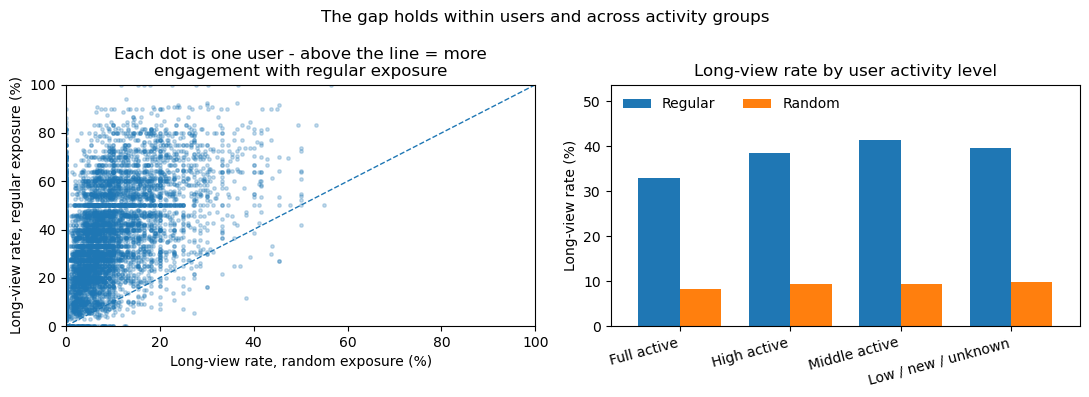

In [15]:
by_group = (compare1.groupby(["activity_group", "exposure"], observed=True)["long_view"].mean().unstack() * 100)
order = ["Full active", "High active", "Middle active", "Low / new / unknown"]
by_group = by_group.reindex(order)[["Regular", "Random"]]
by_group["ratio"] = by_group["Regular"] / by_group["Random"]
print(by_group.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.scatter(paired[("long_view", "Random")] * 100, paired[("long_view", "Regular")] * 100,
           s=6, alpha=0.25)
ax.plot([0, 100], [0, 100], linestyle="--", linewidth=1)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Long-view rate, random exposure (%)")
ax.set_ylabel("Long-view rate, regular exposure (%)")
ax.set_title("Each dot is one user - above the line = more\nengagement with regular exposure")

ax = axes[1]
by_group[["Regular", "Random"]].plot.bar(ax=ax, width=0.75)
ax.set_xlabel("")
ax.set_ylabel("Long-view rate (%)")
ax.set_title("Long-view rate by user activity level")
ax.set_ylim(0, by_group[["Regular", "Random"]].to_numpy().max() * 1.3)
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
ax.legend(title="", frameon=False, loc="upper left", ncol=2)

fig.suptitle("The gap holds within users and across activity groups")
plt.tight_layout()
plt.show()

**What Step 7 shows:**

- **The difference isn't just driven by heavy users:** Among the 8,322 users with at least 10 appearances of each type, 97% clicked more on regular exposures and 95% long-viewed more. The average user's long-view rate was 34.7% under regular exposure vs. 7.3% under random. Likes are rare, and about 79% of these users have the same like rate (usually zero) under both types, so the like rate is best read from the pooled numbers in Step 3.
- **The difference is also consistent across activity levels:** The long-view gap is about 4.0x to 4.4x in every activity group.
- **Pooled ratios:** Regular exposure gets about 2.8x the clicks, 4.2x the likes and 4.1x the long views of random exposure.

**How to read this:** The algorithm picks videos it predicts a user will engage with, so some gap is built in. These are observed differences in engagement, not proof that recommendations changed anyone's preferences. This result can't tell "the algorithm predicted well" apart from "exposure shaped the taste". The next two steps look at earlier topic exposure and feed variety, but they still can't show whether recommendations changed users’ interests.

## Step 8: Does past exposure predict engagement with *randomly shown* videos?
The gap in Step 7 is hard to interpret on its own: the algorithm picks videos it predicts a user will like, so of course those get more engagement. The random exposures let us ask a better question.

1. Use the **history period** (Apr 8-21) to measure what share of each user's algorithm-fed videos fell in each topic `tag`.
2. In the **test period**, look only at *random* exposures. These videos were randomly inserted rather than selected through personalized recommendations.
3. Question: do users engage more with randomly shown videos from their three most-shown history topics than with videos from other topics?

Higher engagement with top-three history topics would be consistent with two possible explanations: the algorithm learned what users already liked, or earlier exposure helped shape their interests. This comparison can't separate those explanations.

### Reshape: build each user's topic profile

In [16]:
MIN_HIST = 20   # require at least 20 history exposures so topic shares are not noise

tagged = logs[logs["tag"] >= 0]            # drop the 1% of videos with no topic tag
hist = tagged[(tagged["period"] == "P1") & (tagged["tab"] == 1)]

# long -> wide: one row per user, one column per tag
tag_counts = hist.groupby(["user_id", "tag"]).size().unstack(fill_value=0)
n_hist = tag_counts.sum(axis=1)
keep_users = n_hist.index[n_hist >= MIN_HIST]
tag_share = tag_counts.loc[keep_users].div(n_hist[keep_users], axis=0)
print("User x tag share matrix:", tag_share.shape, "| rows sum to 1:", bool(np.allclose(tag_share.sum(axis=1), 1)))

# wide -> long, keep non-zero cells, rank each user's tags
profile = tag_share.stack().rename("hist_share").reset_index()
profile = profile[profile["hist_share"] > 0].copy()
profile["hist_rank"] = profile.groupby("user_id")["hist_share"].rank(ascending=False, method="first")
print("Non-zero user-tag pairs:", f"{len(profile):,}")
print(profile.sort_values(["user_id", "hist_rank"]).head(6).to_string())

User x tag share matrix: (13655, 43) | rows sum to 1: True
Non-zero user-tag pairs: 192,007
    user_id  tag  hist_share  hist_rank
6         2    7    0.195122        1.0
35        2   39    0.170732        2.0
8         2    9    0.158537        3.0
5         2    6    0.109756        4.0
11        2   12    0.048780        5.0
16        2   17    0.048780        6.0


### Transform and merge: attach each user's history to their random exposures

In [17]:
test = tagged.loc[(tagged["period"] == "P2") & (tagged["exposure"] == "Random") & (tagged["tab"] == 1)
                  & tagged["user_id"].isin(keep_users),
                  ["user_id", "video_id", "tag", "is_click", "is_like", "long_view"]]

test = test.merge(profile, on=["user_id", "tag"], how="left", validate="m:1")
test["hist_share"] = test["hist_share"].fillna(0)             # tag never shown in history
test["top3_tag"] = test["hist_rank"] <= 3                      # one of the user's 3 most-fed topics

print(f"Random exposures analysed: {len(test):,} across {test['user_id'].nunique():,} users")
print(f"Share of random exposures landing on a user's top-3 history tags: {test['top3_tag'].mean():.1%}\n")

top3_table = test.groupby("top3_tag").agg(exposures=("video_id", "size"),
                                         click_pct=("is_click", "mean"),
                                         like_pct=("is_like", "mean"),
                                         long_view_pct=("long_view", "mean"))
top3_table[["click_pct", "like_pct", "long_view_pct"]] *= 100
top3_table.index = ["Not a top-3 history tag", "Top-3 history tag"]
print(top3_table.round(2).to_string())

Random exposures analysed: 696,036 across 13,647 users
Share of random exposures landing on a user's top-3 history tags: 28.9%

                         exposures  click_pct  like_pct  long_view_pct
Not a top-3 history tag     495019      14.65      0.42           6.72
Top-3 history tag           201017      22.80      0.50          11.26


### Compare users with themselves

Some users simply engage more than others, and those users might also have richer histories. To reduce the influence of those differences, we compare each user **with themselves**: their engagement on random videos from their top-3 history topics vs. random videos from other topics (users need at least 5 random exposures of each kind).

In [18]:
MIN_SIDE = 5

wu = test.groupby(["user_id", "top3_tag"]).agg(n=("video_id", "size"),
                                               click=("is_click", "mean"),
                                               long_view=("long_view", "mean")).unstack("top3_tag")
ok = wu.index[(wu[("n", True)] >= MIN_SIDE) & (wu[("n", False)] >= MIN_SIDE)]
wu = wu.loc[ok]
print(f"Users with >= {MIN_SIDE} random exposures on top-3 tags AND on other tags: {len(wu):,}")

rows = []
for m in ["click", "long_view"]:
    yes, no = wu[(m, True)], wu[(m, False)]
    rows.append({"metric": m,
                 "mean_top3_%": 100 * yes.mean(),
                 "mean_other_%": 100 * no.mean(),
                 "mean_difference_pts": 100 * (yes - no).mean(),
                 "share_users_top3_higher": (yes > no).mean(),
                 "share_users_other_higher": (yes < no).mean()})
print(pd.DataFrame(rows).set_index("metric").round(3).to_string())

Users with >= 5 random exposures on top-3 tags AND on other tags: 9,240
           mean_top3_%  mean_other_%  mean_difference_pts  share_users_top3_higher  share_users_other_higher
metric                                                                                                      
click           21.922        14.355                7.567                    0.639                     0.257
long_view       10.869         6.686                4.183                    0.504                     0.250


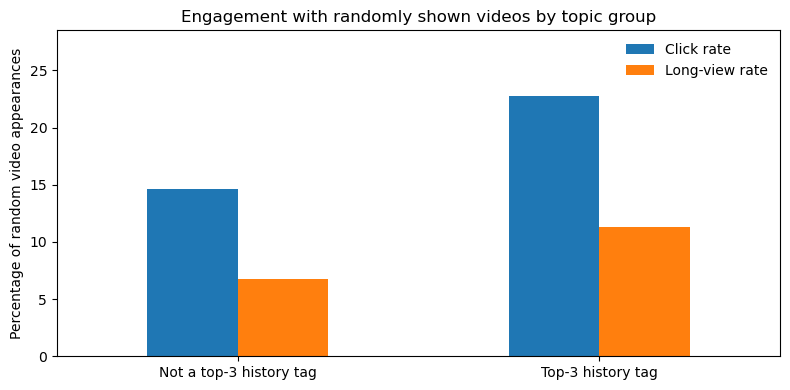

In [19]:
# Compare engagement with top-three history topics and other topics
plot_data = top3_table[["click_pct", "long_view_pct"]].copy()
plot_data.columns = ["Click rate", "Long-view rate"]

ax = plot_data.plot.bar(
    figsize=(8, 4)
)
ax.set_title("Engagement with randomly shown videos by topic group")
ax.set_ylabel("Percentage of random video appearances")
ax.set_xlabel("")
ax.set_ylim(0, plot_data.to_numpy().max() * 1.25)
plt.xticks(rotation=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What Step 8 shows:**

- **Top-3 topics:** About 29% of random exposures happened to land on one of the user's three most-fed topics. Those were clicked on 22.8% of the time vs. 14.7% for other topics, and long-viewed 11.3% vs. 6.7%. Likes barely differ (0.50% vs. 0.42%), which is expected given how rare they are.
- **Holds within users:** Comparing each user with themselves gives the same result. Among 9,240 users, the average click rate was 21.9% on random videos from their top-3 topics and 14.4% on other topics. Long-view rates were 10.9% and 6.7%, respectively. Click rate was higher on top-3 topics for 64% of these users and lower for 26%. Long-view rate was higher for 50% and lower for 25%.

**How this connects to our proposal:** Users engaged more with randomly shown videos when the topic was one of their three most-shown topics in the earlier recommendation history. This is consistent with a possible feedback loop, but it could also mean the algorithm had learned what users already liked. With this data, we can't tell whether recommendations shaped those interests or reflected interests users already had.

This comparison does not account for differences in topic popularity. Some of the gap could come from certain topics generally receiving more engagement.

## Step 9: Narrowing exposure 
*Is the algorithm's feed narrower than a random feed?* We use two simple measures:

- **Topics per user:** How many different topics (tags) appear in a user's feed. More topics means a more varied feed.
- **Video concentration:** We use a simple measure of concentration by looking at what percentage of total video exposures come from the 10% of videos shown most often. This helps us compare whether recommendations are concentrated around a smaller group of videos in the regular feed versus the random feed.

The three groups have very different volumes, and more exposures would naturally show more topics. So we **sample exactly 20 exposures per user** before counting topics, and for concentration we randomly sample the same total number of exposures from every group. 

In [20]:
N_PER_USER = 20
feed = logs[(logs["tab"] == 1) & (logs["tag"] >= 0)]
groups = {"Standard, Apr 8-21":  feed[(feed["period"] == "P1")],
          "Standard, Apr 22-May 8": feed[(feed["period"] == "P2") & (feed["exposure"] == "Regular")],
          "Random, Apr 22-May 8": feed[(feed["period"] == "P2") & (feed["exposure"] == "Random")]}

def topics_per_user(df, n=N_PER_USER, seed=42):
    # Number of distinct topics among n randomly sampled exposures per user.
    sizes = df.groupby("user_id").size()
    df = df[df["user_id"].isin(sizes.index[sizes >= n])]
    sample = df.groupby("user_id", group_keys=False).sample(n=n, random_state=seed)
    return sample.groupby("user_id")["tag"].nunique()

topics = {name: topics_per_user(df) for name, df in groups.items()}
summary3 = pd.DataFrame({name: {"users_analysed": len(t),
                                "median_topics": t.median(),
                                "mean_topics": t.mean()}
                         for name, t in topics.items()}).T
print(summary3.round(2).to_string())
print(f"(Each user is judged on {N_PER_USER} exposures, so the most topics possible is {N_PER_USER}.)")

                        users_analysed  median_topics  mean_topics
Standard, Apr 8-21             13655.0            9.0         9.27
Standard, Apr 22-May 8          2541.0           10.0         9.83
Random, Apr 22-May 8           14689.0           12.0        11.95
(Each user is judged on 20 exposures, so the most topics possible is 20.)


In [21]:
a = topics["Standard, Apr 8-21"]
b = topics["Random, Apr 22-May 8"]
common = a.index.intersection(b.index)
diff = b.loc[common] - a.loc[common]
print(f"Same {len(common):,} users in both feeds: median topics, standard = {a.loc[common].median():.0f}, "
      f"random = {b.loc[common].median():.0f}")
print(f"Random feed has more topics for {(diff > 0).mean():.1%} of these users, "
      f"fewer for {(diff < 0).mean():.1%}, the same for {(diff == 0).mean():.1%}\n")

# Does narrowing differ by how active the user is?
act = users.set_index("user_id")["activity_group"]
tab_act = pd.DataFrame({"Standard": a.loc[common], "Random": b.loc[common]})
tab_act["activity_group"] = act.reindex(tab_act.index).values
print("Median topics per user, by activity group:")
print(tab_act.groupby("activity_group")[["Standard", "Random"]].median().reindex(order).to_string())

Same 7,877 users in both feeds: median topics, standard = 9, random = 12
Random feed has more topics for 78.7% of these users, fewer for 11.4%, the same for 9.9%

Median topics per user, by activity group:
                     Standard  Random
activity_group                       
Full active               9.0    12.0
High active               9.0    12.0
Middle active             9.0    12.0
Low / new / unknown      10.0    12.0


In [22]:
# Concentration: equal-size samples of exposures from each group, counted over the full video pool
N_EXPO = min(len(df) for df in groups.values())
pool = videos["video_id"]

def top10_share(df):
    # Share of exposures that go to the most-shown 10% of videos
    counts = (df.sample(n=N_EXPO, random_state=42)["video_id"].value_counts()
                .reindex(pool, fill_value=0).sort_values().to_numpy())
    return counts[-int(0.1 * len(counts)):].sum() / counts.sum() * 100

top10 = {name: top10_share(df) for name, df in groups.items()}
print(f"Exposures sampled per group: {N_EXPO:,}  |  Videos in pool: {len(pool):,}\n")
print("Share of exposures going to the most-shown 10% of videos:")
for name, value in top10.items():
    print(f"  {name:<24} {value:.1f}%")

Exposures sampled per group: 221,578  |  Videos in pool: 7,583

Share of exposures going to the most-shown 10% of videos:
  Standard, Apr 8-21       63.6%
  Standard, Apr 22-May 8   67.9%
  Random, Apr 22-May 8     14.0%


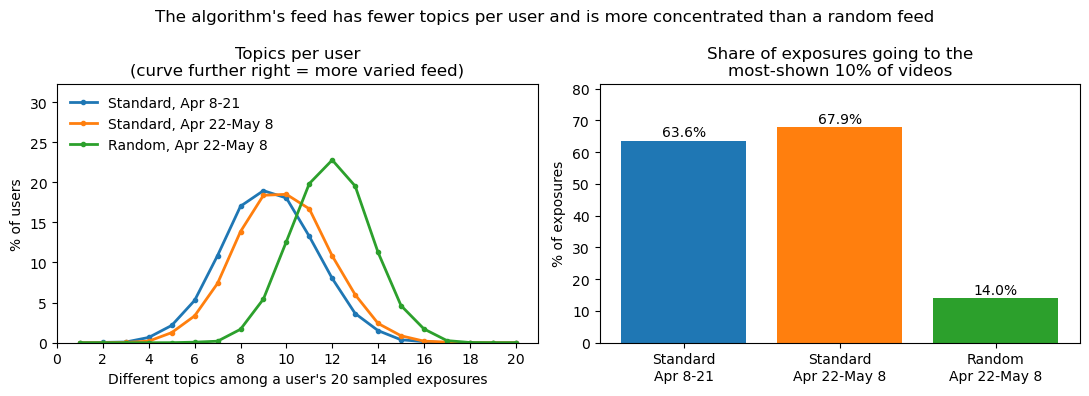

In [23]:
# keep consistent colors from analysis above
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
for name, t in topics.items():
    share = t.value_counts(normalize=True).reindex(range(1, N_PER_USER + 1), fill_value=0) * 100
    ax.plot(share.index, share.values, marker="o", markersize=3, linewidth=2, label=name)
ax.set_xlabel("Different topics among a user's 20 sampled exposures")
ax.set_ylabel("% of users")
ax.set_title("Topics per user\n(curve further right = more varied feed)")
ax.set_xticks(range(0, N_PER_USER + 1, 2))
ax.set_ylim(0, ax.get_ylim()[1] * 1.35)
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
names = list(top10.keys())
vals = [top10[n] for n in names]
ax.bar([n.replace(", ", "\n") for n in names], vals, color=[f"C{i}" for i in range(len(names))])
ax.set_ylabel("% of exposures")
ax.set_ylim(0, max(vals) * 1.2)
ax.set_title("Share of exposures going to the\nmost-shown 10% of videos")
for position, value in enumerate(vals):
    ax.text(position, value + max(vals) * 0.02, f"{value:.1f}%", ha="center")

fig.suptitle("The algorithm's feed has fewer topics per user and is more concentrated than a random feed")
plt.tight_layout()
plt.show()

**What Step 9 shows:**

- **Fewer topics per user:** Out of 20 sampled appearances, the typical user saw 9 different topics in the algorithm's feed and 12 in the random feed. Comparing the April 8–21 regular feed with the later random exposures for the same 7,877 users, random exposures included more topics for 78.7%, fewer for 11.4%, and the same number for 9.9%.
- **More concentrated across videos:** The most-shown 10% of videos received 63.6% (Apr 8-21) and 67.9% (Apr 22-May 8) of the algorithm's exposures, compared with 14% under random exposure.
- **Similar across activity levels:** The typical user saw 9 or 10 topics under regular exposure and 12 under random exposure in every activity group. Heavier users do not have noticeably narrower feeds on this measure.

**Keep in mind:**

- **Comparing the two periods:** The regular-feed logs cover different groups of users, with fewer users in the later period. They help us compare the feeds, but we'd need to track the same users over time to see whether their feeds become narrower.
- **Using random exposure as a comparison:** Randomly shown videos give us a useful baseline for content variety. Personalized recommendations focus on what users might like, so a more concentrated feed does not automatically mean a worse experience.
- **What these results tell us:** The regular feed included fewer topics and was more concentrated than the random feed in this sample. To examine whether recommendations move toward more extreme content, we would also need to know what topics the numbered tags actually refer to.

# Connection to our proposal: 
Our proposal looks at how recommendations can shape behavior that then influences future recommendations. In our sample, users clicked, liked, and watched longer more often on regular recommendations than on randomly shown videos. The click and long-view differences also held when comparing the same users, and the long-view gap appeared across activity levels. This matters because the engagement data a platform collects depends partly on what it shows users. That data tells us how users responded to those videos, but it does not give us a complete picture of their interests.

If the platform uses that engagement to recommend more similar videos, it could reinforce its earlier predictions. Our analysis shows the exposure and response parts of this possible loop. We did not test whether the platform then recommended more similar content or whether users’ interests changed. Following the same users over a longer period could help examine those questions, although we would still need a way to separate the influence of recommendations from users’ existing interests.

For businesses, this shows why engagement alone does not tell the whole story. Higher engagement may mean recommendations are matching users’ interests well. Looking at content variety and long-term satisfaction alongside engagement would give a fuller picture of the user experience.

**What Steps 6-9 add:** Step 8 shows that users engaged more with randomly shown videos from their three most-shown topics in their earlier recommendation history than with videos from other topics. The same pattern appeared when comparing users with themselves. This fits with a possible feedback loop, but it could also mean the algorithm had learned what users already liked. Some topics may also get more engagement in general, which this comparison does not account for.

Step 9 shows that the regular feed included fewer topics per user and concentrated more appearances among a smaller group of videos than the random feed. This helps describe how focused the recommendations were in our sample. It does not show that an individual user’s feed became narrower over time. To study whether recommendations move toward more extreme content, we would also need to know what topics the numbered tags actually refer to.

## Sources
**Dataset & field definitions:** https://kuairand.com/

**Dataset Paper:** Gao et al. (2022), KuaiRand: An Unbiased Sequential Recommendation Dataset with Randomly Exposed Videos. https://arxiv.org/abs/2208.08696